# Análise exploratória do TrashNet

Este notebook inspeciona o `dataset-resized.zip`, descreve integridade, dimensões e canais, mostra exemplos das seis classes e grava a divisão estratificada usada em todos os experimentos.

A divisão é 70% treino, 15% validação e 15% teste, com semente 42. Nenhum arquivo aparece em mais de um conjunto.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import runpy
_ = runpy.run_path(str(ROOT / "scripts" / "preparar_dados.py"), run_name="__main__")


Dataset: data/dataset-resized
Válidas: 2527 de 2527
Dimensões: {'512x384': 2527}
Modos: {'RGB': 2527}
Canais: {'3': 2527}
Formatos: {'JPEG': 2527}
Problemas: 0
treino {'glass': 350, 'paper': 416, 'cardboard': 282, 'plastic': 337, 'metal': 287, 'trash': 96} total 1768
validacao {'glass': 75, 'paper': 89, 'cardboard': 61, 'plastic': 72, 'metal': 61, 'trash': 21} total 379
teste {'glass': 76, 'paper': 89, 'cardboard': 60, 'plastic': 73, 'metal': 62, 'trash': 20} total 380


In [2]:
import json
import pandas as pd
from IPython.display import Image, display, Markdown

eda = json.loads((ROOT / "artifacts" / "eda.json").read_text(encoding="utf-8"))
divisao = json.loads((ROOT / "artifacts" / "divisao.json").read_text(encoding="utf-8"))

print("Raiz:", eda["raiz_dataset"])
print("Arquivos válidos:", eda["total_validos"], "de", eda["total_arquivos"])
print("Formatos:", eda["formatos"])
print("Modos de cor:", eda["modos"])
print("Canais:", eda["canais"])
print("Dimensões:", eda["dimensoes"])
print("Arquivos com falha:", eda["problemas"])

tabela = pd.DataFrame(divisao["contagens"]).T
tabela["total"] = tabela.sum(axis=1)
display(tabela)


Raiz: data/dataset-resized
Arquivos válidos: 2527 de 2527
Formatos: {'JPEG': 2527}
Modos de cor: {'RGB': 2527}
Canais: {'3': 2527}
Dimensões: {'512x384': 2527}
Arquivos com falha: []


,glass,paper,cardboard,plastic,metal,trash,total
treino,350,416,282,337,287,96,1768
validacao,75,89,61,72,61,21,379
teste,76,89,60,73,62,20,380


In [3]:
from src.dados import duplicatas_por_conteudo, localizar_dataset

# Arquivos com o mesmo conteúdo (SHA-256 igual), com a classe e o conjunto de cada um.
duplicadas = duplicatas_por_conteudo(localizar_dataset(), divisao)
print("Grupos de arquivos idênticos:", len(duplicadas))
display(pd.DataFrame([{"grupo": i + 1, **item} for i, grupo in enumerate(duplicadas) for item in grupo]))


Grupos de arquivos idênticos: 3


,grupo,arquivo,classe,conjunto
0,1,glass115.jpg,glass,treino
1,1,metal91.jpg,metal,treino
2,2,glass176.jpg,glass,treino
3,2,plastic152.jpg,plastic,treino
4,3,glass389.jpg,glass,treino
5,3,plastic332.jpg,plastic,validacao


### Imagens por classe em treino, validação e teste

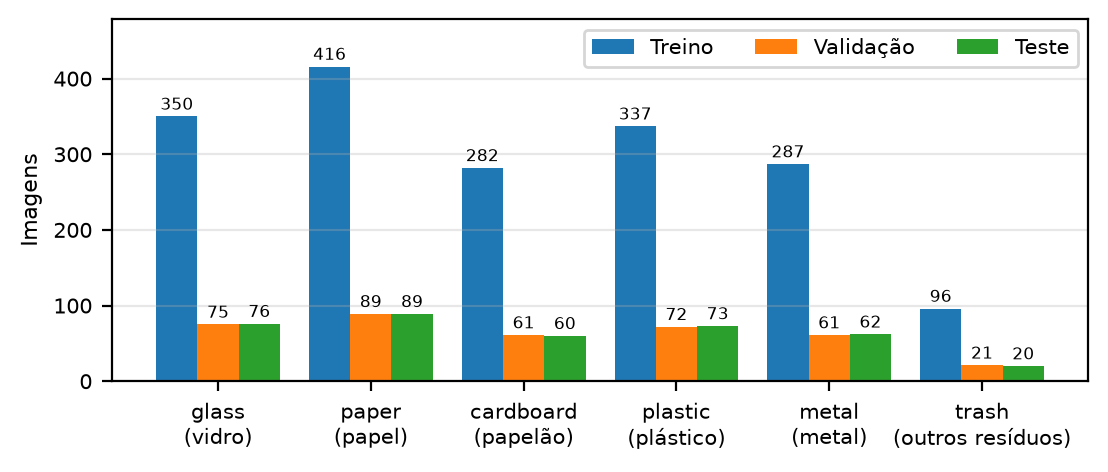

### Dois exemplos de cada classe

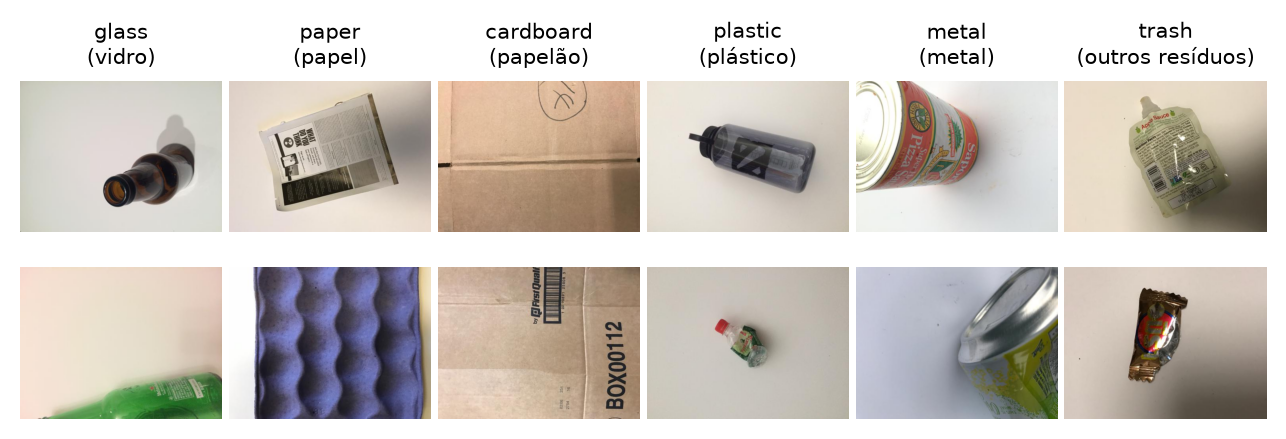

### A mesma imagem nas três resoluções

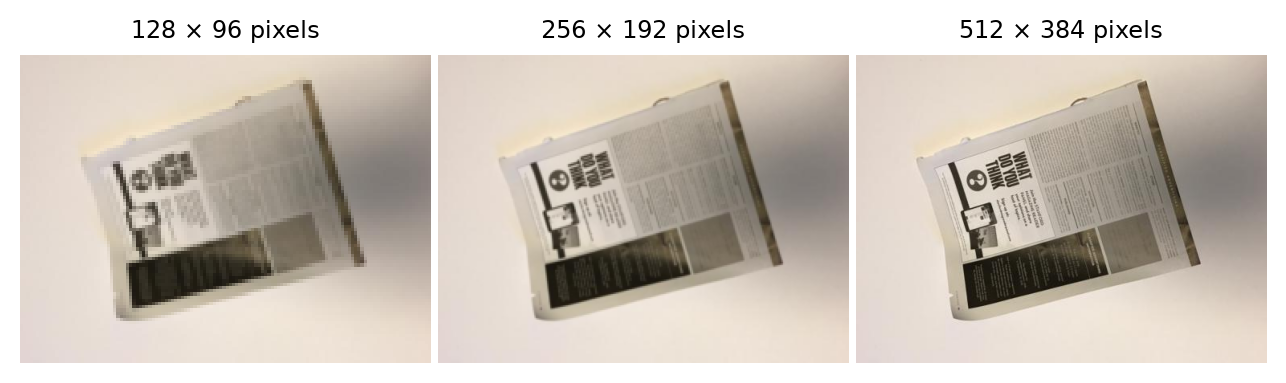

In [4]:
TITULOS = {
    "distribuicao_classes.png": "Imagens por classe em treino, validação e teste",
    "exemplos_classes.png": "Dois exemplos de cada classe",
    "exemplo_resolucoes.png": "A mesma imagem nas três resoluções",
}
for nome, titulo in TITULOS.items():
    display(Markdown(f"### {titulo}"))
    display(Image(filename=str(ROOT / "artifacts" / "figuras" / nome)))

## O que dificulta a classificação

As fotos foram feitas com o objeto sobre um fundo claro, em geral branco, com iluminação de sol ou de interior. Isso deixa o problema mais fácil do que uma foto de lixeira real, mas ainda há confusões previsíveis:

- Vidro e plástico são transparentes ou translúcidos e compartilham reflexos.
- Metal também reflete e, em latinhas, se aproxima do vidro e do plástico pelo formato cilíndrico.
- Papel e papelão diferem sobretudo pela espessura e pela cor parda, que nem sempre aparecem.
- A classe trash reúne objetos heterogêneos e tem bem menos exemplos que as outras.

## Tratamento adotado

Todas as 2.527 imagens abriram sem erro e são JPEG RGB de 512 × 384. A comparação do conteúdo dos arquivos achou três pares de fotos idênticas com rótulos diferentes (tabela de arquivos idênticos, acima). Os pares foram mantidos, para não alterar o dataset nem a divisão já usada nos treinos: nenhum deles está no teste, e só o par glass389 e plastic332 tem uma foto no treino e a outra na validação. Na carga, o redimensionamento é bilinear. A normalização é fixa, `(pixel / 255) - 0,5`, a mesma em treino, validação e teste. Dividir só por 255 deixava a média perto de 0,64 por causa do fundo branco, e a MLP não saía da classe majoritária. O ensaio auxiliar registra isso (`scripts/ensaio_normalizacao.py`, resultado em `artifacts/ensaios/ensaio_normalizacao.json`): com só /255, a média dos pixels de treino foi 0,639 e a MLP 128 × 96 previu paper, a classe mais frequente, para as 379 imagens de validação. Não há aumento de dados nos seis experimentos controlados: cada arquivo permanece em um único conjunto.